<a href="https://colab.research.google.com/github/laksamanaap/PCVK_Ganjil_2026/blob/main/P6/Week6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [110]:
# Import gdrive dan library
from google.colab import drive
drive.mount('/content/drive')

import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
import math
from google.colab.patches import cv2_imshow
from PIL import Image as im

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [111]:
# Konvulusi tanpa library
def convolution2d(image, kernel, stride, padding):
    # size gambar dan kernel
    image_h, image_w = image.shape
    kernel_h, kernel_w = kernel.shape

    # padding
    padded_image = np.pad(
        image,
        ((padding, padding), (padding, padding)),
        mode='constant'
    )

    # hitung output
    output_h = ((image_h + 2 * padding - kernel_h) // stride) + 1
    output_w = ((image_w + 2 * padding - kernel_w) // stride) + 1

    # matriks output
    output = np.zeros((output_h, output_w))

    # balik kernel untuk konvolusi
    kernel = np.flipud(np.fliplr(kernel))

    # proses konvolusi
    for y in range(output_h):
        for x in range(output_w):
            # tentukan posisi awal
            y_start = y * stride
            x_start = x * stride

            # ambil bagian gambar sesuai ukuran kernel
            region = padded_image[
                y_start:y_start + kernel_h,
                x_start:x_start + kernel_w
            ]

            # kalikan elemen lalu dijumlahkan
            output[y, x] = np.sum(region * kernel)

    return output

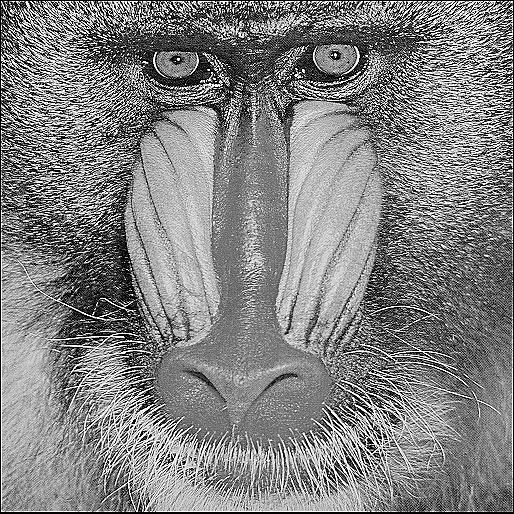

In [112]:
img = cv.imread('/content/drive/MyDrive/PCVK_img/mandrill.tiff')
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# img sharpening
kernel_sharpen = np.array([[0,-1,0], [-1,5,-1], [0,-1,0]])
cv2_imshow(convolution2d(img_gray, kernel_sharpen, 1, 2))

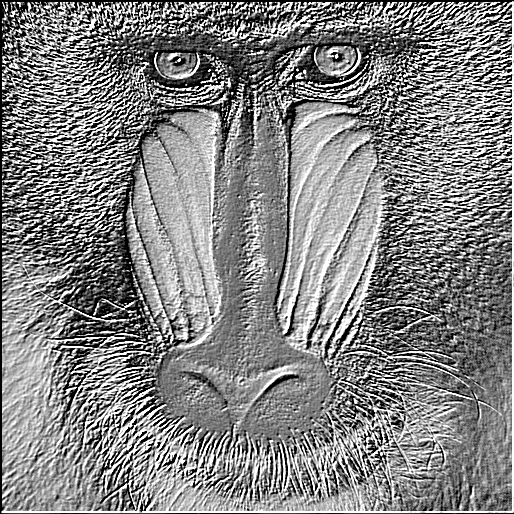

In [113]:
# img emboss
kernel_emboss = np.array([[-2,-1,0], [-1,1,1], [0,1,2]])
cv2_imshow(convolution2d(img_gray, kernel_emboss, 1, 2))

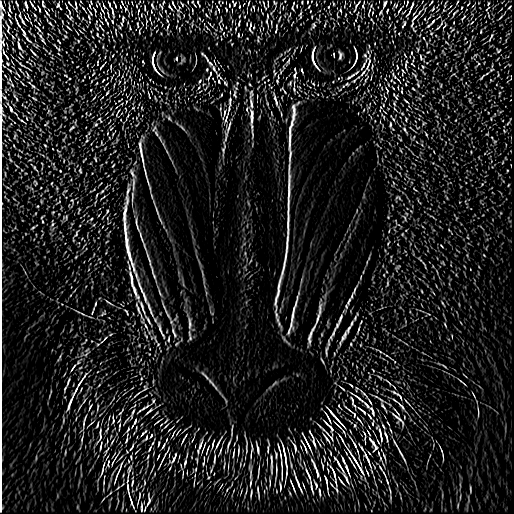

In [114]:
# img left sabel edge detection
kernel_left_sobel_edge_detection = np.array([[1,0,-1], [2,0,-2], [1,0,-1]])
cv2_imshow(convolution2d(img_gray, kernel_left_sobel_edge_detection, 1, 2))

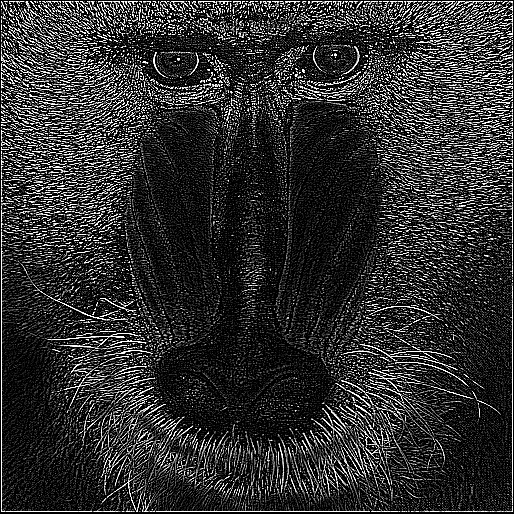

In [115]:
# img canny edge detection
kernel_canny_edge_detection = np.array([[-1,-1,-1], [-1,8,-1], [-1,-1,-1]])
cv2_imshow(convolution2d(img_gray, kernel_canny_edge_detection, 1, 2))

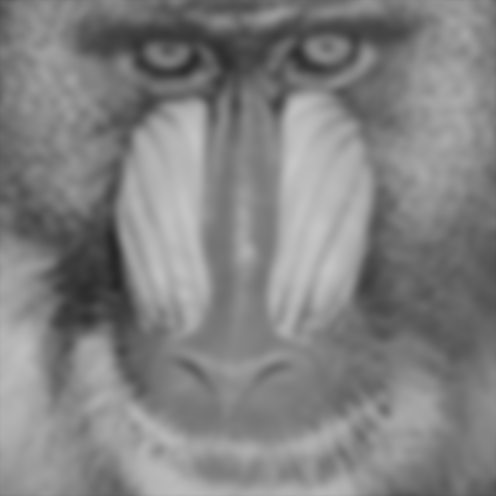

In [116]:
# 21x21 gaussian
kernel_size = 21

sigma=math.sqrt(kernel_size)
gaussian_kernel = cv.getGaussianKernel(kernel_size, sigma)
gauss_kernel = gaussian_kernel @ gaussian_kernel.transpose()

cv2_imshow(convolution2d(img_gray, gauss_kernel, 1, 2))

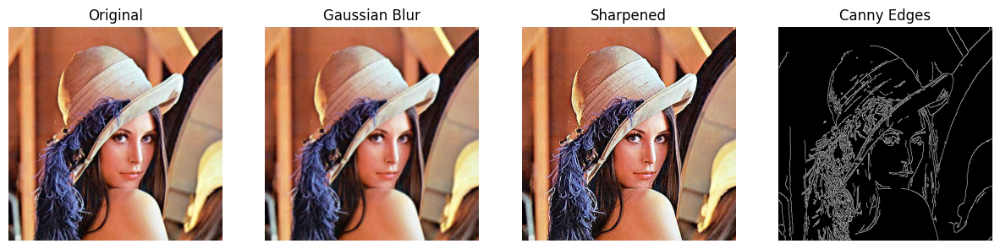

In [117]:
# fungsi tampil berdampingan
def show_side_by_side(images, titles, figsize=(15, 5)):
    plt.figure(figsize=figsize)
    for i, (img, title) in enumerate(zip(images, titles)):
        if len(img.shape) == 2: # gray
            plt.subplot(1, len(images), i+1)
            plt.imshow(img, cmap="gray")
        else:
            plt.subplot(1,  len(images), i+1)
            plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
        plt.title(title)
        plt.axis("off")
    plt.show()

img = cv.imread('/content/drive/MyDrive/PCVK_img/lena.jpg')
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

blur = cv.GaussianBlur(img, (7, 7), 1)
edges = cv.Canny(cv.cvtColor(img, cv.COLOR_BGR2GRAY), 100, 200)
sharpen_kernel = np.array([[0,-1,0], [-1,5,-1], [0,-1,0]])
sharpened = cv.filter2D(img, -1, sharpen_kernel)
show_side_by_side([img, blur, sharpened, edges], ["Original", "Gaussian Blur", "Sharpened", "Canny Edges"])

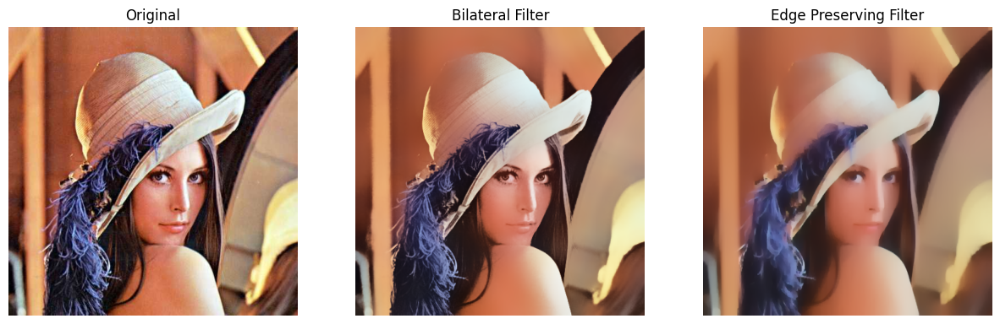

In [118]:
# filter modern open cv
# bilateral filter (edge-preserving filter)
bilateral = cv.bilateralFilter(img, 50, 100, 100)

# edge preserving filter (edge-preserving filter)
edge_preserve = cv.edgePreservingFilter(img, flags=1, sigma_s=100, sigma_r=0.9)

show_side_by_side([img, bilateral, edge_preserve], ["Original", "Bilateral Filter", "Edge Preserving Filter"])

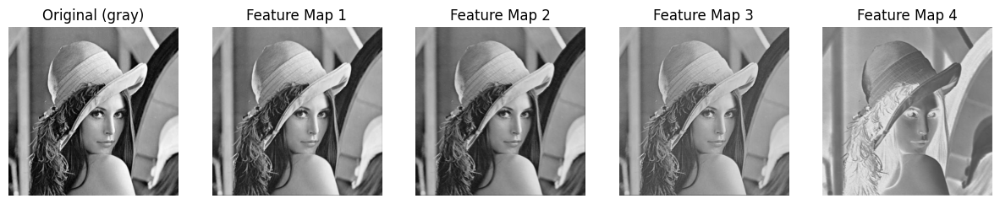

In [119]:
# filtering pada cnn (feature map)
import torch
import torch.nn as nn

class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self,).__init__()
        self.conv1 = nn.Conv2d(1, 4, kernel_size=3, stride=1, padding=1)

    def forward(self, x):
        return self.conv1(x)

model = SimpleCNN()

# ubah gambar ke tensor
img_tensor = torch.tensor(img_gray, dtype=torch.float32).unsqueeze(0).unsqueeze(0) / 255.0

# hasil CNN
with torch.no_grad():
    features = model(img_tensor)

# visualisasi feature map
feature_map = [features[0,i].numpy() for i in range(features.shape[1])]
show_side_by_side([img_gray] + feature_map, ["Original (gray)"] + [f"Feature Map {i+1}" for i in range(len(feature_map))])

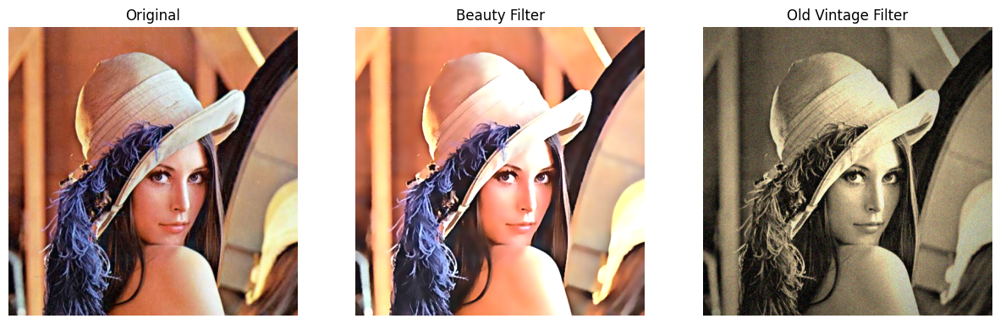

In [120]:
# beauty filter
# step 1
smooth = cv.bilateralFilter(img, d=15, sigmaColor=75, sigmaSpace=75)

# step 2
gaussian = cv.GaussianBlur(smooth, (0, 0), 3)
sharpened = cv.addWeighted(smooth, 1.5, gaussian, -0.5, 0)

# step 3
alpha = 1.2
beta = 15
beauty = cv.convertScaleAbs(sharpened, alpha=alpha, beta=beta)

# old vintage filter
# step 1 sepia tone
sepia_kernel = np.array([[0.272, 0.534, 0.131],
                         [0.349, 0.686, 0.168],
                         [0.393, 0.769, 0.189]])
sepia = cv.transform(img, sepia_kernel)
sepia = np.clip(sepia, 0, 255).astype(np.uint8)

# step 2 vignette effect
rows, cols = img.shape[:2]
kernel_x = cv.getGaussianKernel(cols, cols*0.6)
kernel_y = cv.getGaussianKernel(rows, rows*0.6)
kernel = kernel_y * kernel_x.T
mask = kernel / kernel.max()
vignette = np.copy(sepia)
for i in range(3):
    vignette[:,:,i] = vignette[:,:,i] * mask

# step 3 notes grain
noise = np.random.normal(0, 15, vignette.shape).astype(np.int16)
old_img = np.clip(vignette.astype(np.int16) + noise, 0, 255).astype(np.uint8)

show_side_by_side([img, beauty, old_img], ["Original", "Beauty Filter", "Old Vintage Filter"])

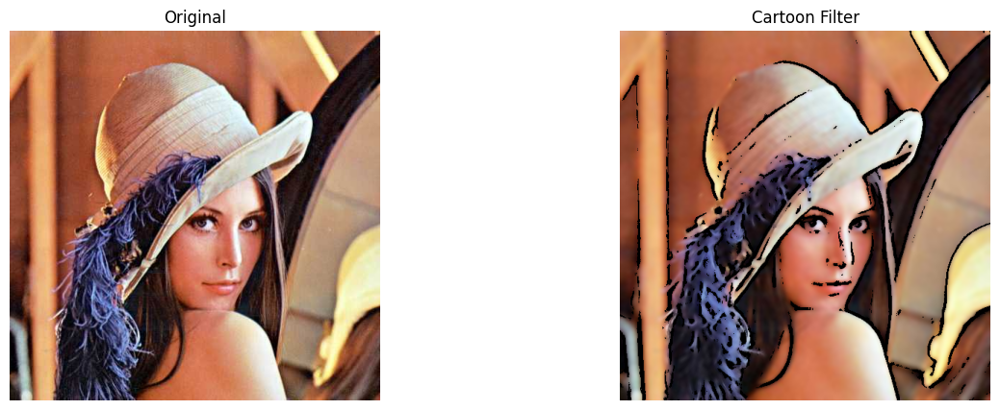

In [121]:
# filter anime / kartun
# step 1 edge detection
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
gray_blur = cv.medianBlur(gray, 7)
edges = cv.adaptiveThreshold(gray_blur, 255, cv.ADAPTIVE_THRESH_MEAN_C, cv.THRESH_BINARY, 9, 9)

# step 2 bilateral filter untuk smoothing warna
color = cv.bilateralFilter(img, d=9, sigmaColor=200, sigmaSpace=200)

# step 3 gabungkan
cartoon = cv.bitwise_and(color, color, mask=edges)

# tampilan
show_side_by_side([img, cartoon], ["Original", "Cartoon Filter"])

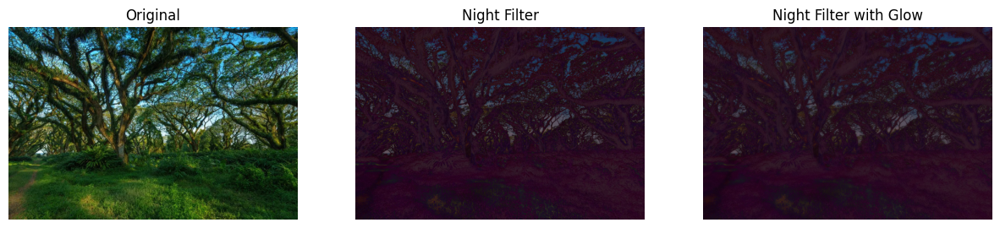

In [122]:
# night filter
img =  cv.imread('/content/drive/MyDrive/PCVK_img/djawatan.jpg')
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# step 1 gelapkan
night = cv.convertScaleAbs(img, alpha=0.6, beta=-40)

# step 2 tambah bias biru
blue_tint = np.full_like(night, (50, 0, 100))  # Create a blue tint
night = cv.addWeighted(night, 0.8, blue_tint, 0.2, 0)

# step 3 efek glow di area terang dengan filter=20 (blur kernel)
kernel = np.ones((15,15), np.float32) / 225
glow = cv.filter2D(night, -1, kernel)

# kombinasikan glow dengan gambar asli
night_glow = cv.addWeighted(night, 0.7, glow, 0.3, 0)

show_side_by_side([img, night, night_glow], ["Original", "Night Filter", "Night Filter with Glow"])

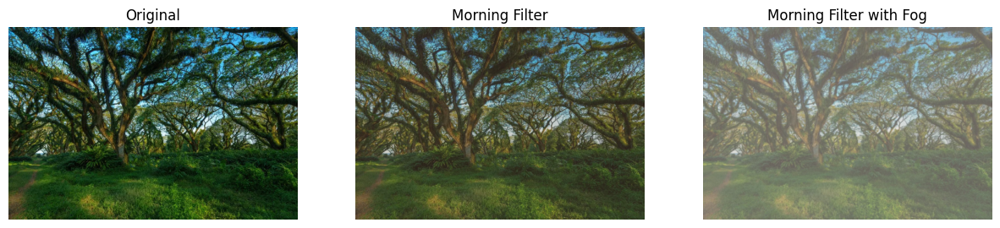

In [123]:
# filter suasana pagi dan kabut
# step 1 kurangi kontras dan cerahkan
alpha = 0.9
beta = 20
soft = cv.convertScaleAbs(img, alpha=alpha, beta=beta)

# step 2 tambahkan warm tone
warm_tint = np.full_like(soft, (40, 70, 120))  # Create a warm tint
pagi = cv.addWeighted(soft, 0.8, warm_tint, 0.2, 0)

# tambahkan haze (kabut tipis) dengan filter2D
# kernel blur gaussian like untuk menciptakan efek kabut
kernel = cv.getGaussianKernel(3, 3)
kernel = kernel @ kernel.T # jadikan kernel 2D
kabut = cv.filter2D(pagi, -1, kernel)

# tambahkan layer putih untuk kabut lebih nyata
white_layer = np.full_like(kabut, 255)
kabut = cv.addWeighted(kabut, 0.7, white_layer, 0.3, 0)

show_side_by_side([img, pagi, kabut], ["Original", "Morning Filter", "Morning Filter with Fog"])

## Tugas Praktikum

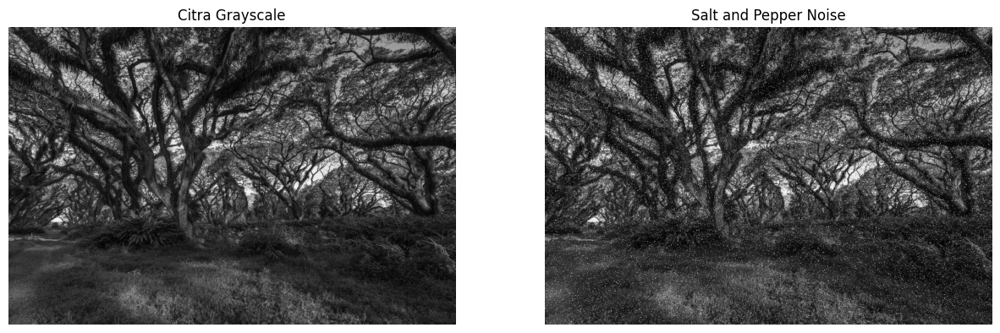

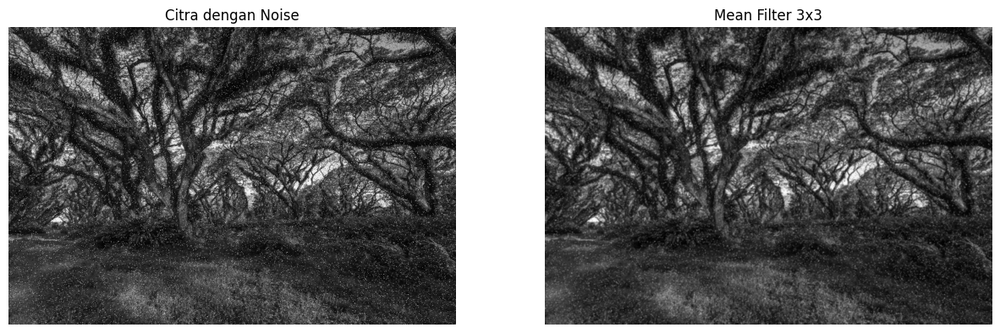

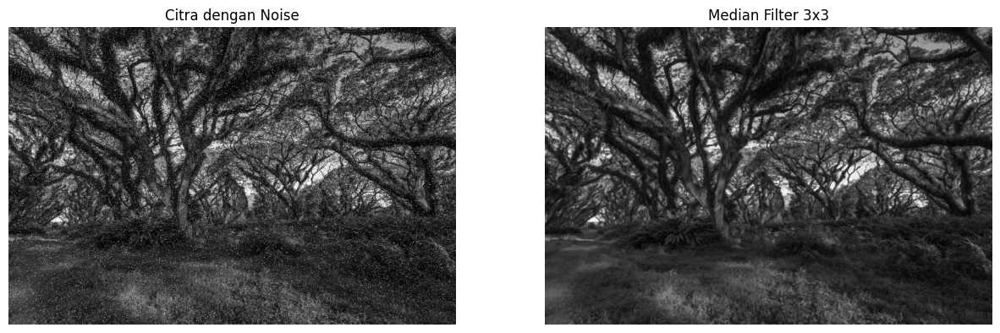

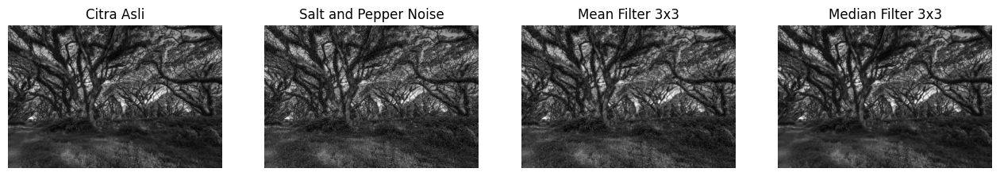

In [124]:
# NOMOR 1 (SALT AND PEPPER)
def add_salt_pepper_noise(image, amount=0.05):
    noisy = image.copy()

    total_pixels = image.size
    num_noise = int(total_pixels * amount)

    num_salt = num_noise // 2
    num_pepper = num_noise - num_salt

    # tambah bintik putih
    y = np.random.randint(0, image.shape[0], num_salt)
    x = np.random.randint(0, image.shape[1], num_salt)
    noisy[y, x] = 255

    # tambah bintik hitam
    y = np.random.randint(0, image.shape[0], num_pepper)
    x = np.random.randint(0, image.shape[1], num_pepper)
    noisy[y, x] = 0

    return noisy


np.random.seed(42)

noisy_gray = add_salt_pepper_noise(img_gray)

show_side_by_side(
    [img_gray, noisy_gray],
    ["Citra Grayscale", "Salt and Pepper Noise"]
)

# mean filter
mean_filtered = cv.blur(noisy_gray, (3, 3))

show_side_by_side(
    [noisy_gray, mean_filtered],
    ["Citra dengan Noise", "Mean Filter 3x3"]
)

# median filter 3x3
median_filtered = cv.medianBlur(noisy_gray, 3)

show_side_by_side(
    [noisy_gray, median_filtered],
    ["Citra dengan Noise", "Median Filter 3x3"]
)

# compare semua hasil
show_side_by_side(
    [
        img_gray,
        noisy_gray,
        mean_filtered,
        median_filtered
    ],
    [
        "Citra Asli",
        "Salt and Pepper Noise",
        "Mean Filter 3x3",
        "Median Filter 3x3"
    ],
    figsize=(16, 5)
)


## Kesimpulan tugas 1
Berdasarkan hasil tugas 1, Mean Filter 3×3 mengurangi noise dengan menghitung rata-rata nilai piksel di sekitar piksel pusat. Namun, piksel noise yang bernilai 0 dan 255 memengaruhi perhitungan rata-rata sehingga citra dapat menjadi lebih buram.

Median Filter 3×3 menggunakan nilai tengah dari piksel-piksel di dalam kernel. Metode ini lebih efektif dalam mengurangi bintik hitam dan putih karena nilai ekstrem tidak terlalu memengaruhi hasil penyaringan.

Kesimpulan: Median Filter 3×3 lebih sesuai untuk menghilangkan Salt and Pepper Noise dibandingkan Mean Filter 3×3 karena mampu mengurangi noise dengan lebih baik sekaligus mempertahankan detail tepi citra

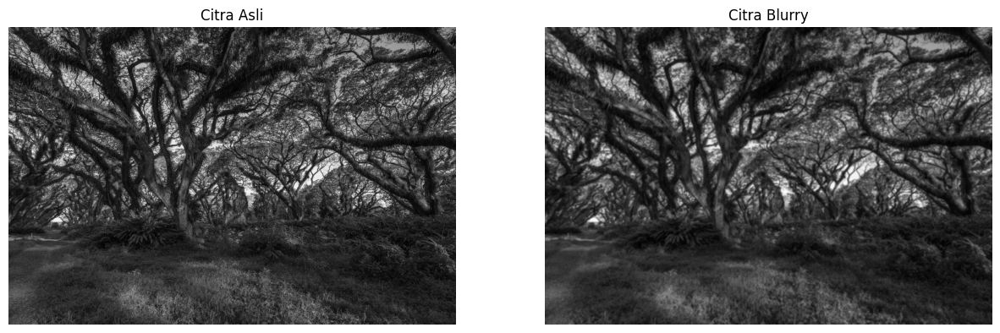

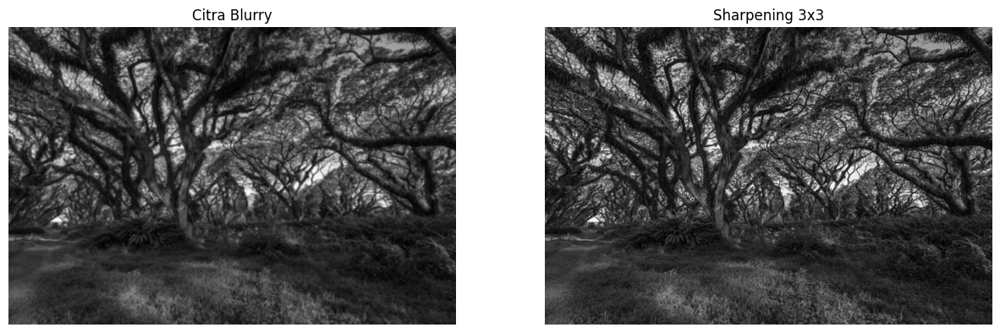

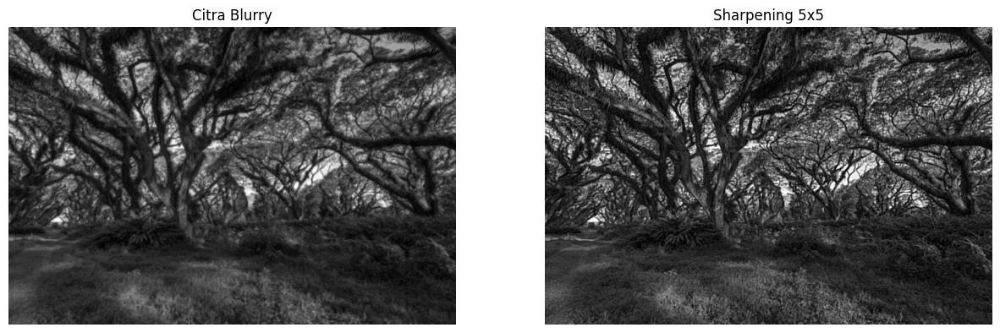

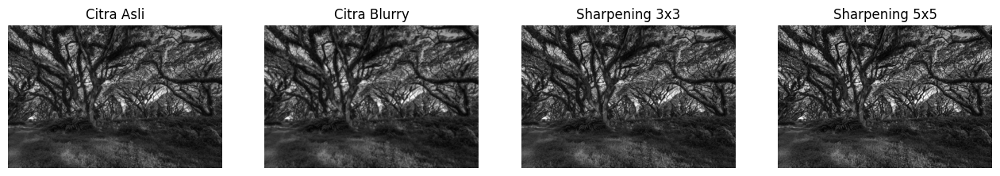

Citra Blurry : 77.94136161942671
Sharpening 3x3: 485.06630554173626
Sharpening 5x5: 343.05634737872464


In [125]:
# NOMOR 2 (CITRA BLURRY)

blurry = cv.GaussianBlur(
    img_gray,
    (5, 5),
    sigmaX=1.2
)

show_side_by_side(
    [img_gray, blurry],
    ["Citra Asli", "Citra Blurry"]
)

# kernel sharpening 3x3

kernel_3x3 = np.array([
    [ 0, -1,  0],
    [-1,  5, -1],
    [ 0, -1,  0]
], dtype=np.float32)

# terapkan kernel pada citra blurry
sharp_3x3 = cv.filter2D(
    blurry,
    -1,
    kernel_3x3
)

show_side_by_side(
    [blurry, sharp_3x3],
    ["Citra Blurry", "Sharpening 3x3"]
)

# kernel sharpening 5x5
kernel_5x5 = np.array([
    [-1, -1, -1, -1, -1],
    [-1,  2,  2,  2, -1],
    [-1,  2,  8,  2, -1],
    [-1,  2,  2,  2, -1],
    [-1, -1, -1, -1, -1]
], dtype=np.float32) / 8.0

# Terapkan kernel pada citra blurry
sharp_5x5 = cv.filter2D(
    blurry,
    -1,
    kernel_5x5
)

show_side_by_side(
    [blurry, sharp_5x5],
    ["Citra Blurry", "Sharpening 5x5"]
)

# tampilkan semua hasil
show_side_by_side(
    [
        img_gray,
        blurry,
        sharp_3x3,
        sharp_5x5
    ],
    [
        "Citra Asli",
        "Citra Blurry",
        "Sharpening 3x3",
        "Sharpening 5x5"
    ],
    figsize=(16, 5)
)

# evaluasi

# Mengukur kekuatan tepi citra

def edge_strength(image):
    return cv.Laplacian(
        image,
        cv.CV_64F
    ).var()

print("Citra Blurry :", edge_strength(blurry))
print("Sharpening 3x3:", edge_strength(sharp_3x3))
print("Sharpening 5x5:", edge_strength(sharp_5x5))


## Kesimpulan tugas 2
Pada tugas 2, citra grayscale dibuat sedikit buram menggunakan Gaussian Blur. Selanjutnya, proses penajaman dilakukan menggunakan kernel Sharpening 3×3 dan 5×5.

Kernel 3×3 memproses area piksel yang lebih kecil sehingga penajaman cenderung lebih terkontrol. Sementara itu, kernel 5×5 melibatkan area tetangga yang lebih luas dan dapat menghasilkan perubahan tepi yang lebih kuat, tetapi juga berpotensi menimbulkan noise atau distorsi.

Evaluasi dilakukan dengan mengamati kejelasan tepi, detail citra, dan kemungkinan munculnya artefak. Varians Laplacian digunakan sebagai pengukuran tambahan untuk melihat kekuatan perubahan intensitas pada citra.

Kesimpulan: Kernel 3×3 dapat menjadi pilihan yang lebih praktis untuk penggunaan sehari-hari apabila hasilnya sudah cukup tajam dan minim distorsi. Kernel 5×5 dapat dipertimbangkan ketika dibutuhkan penajaman yang lebih kuat, tetapi hasil visualnya perlu diperiksa untuk memastikan noise tidak bertambah secara berlebihan

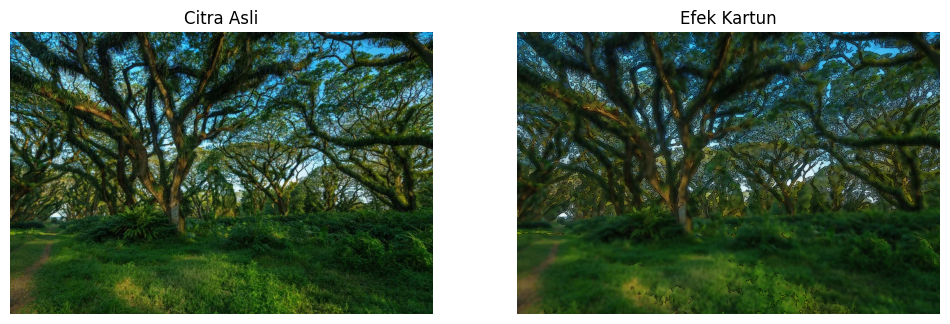

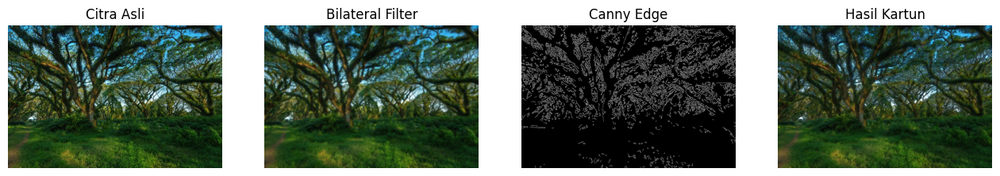

In [126]:
# NOMOR 3 (FILTER KARTUN)

def kartun(image):
    # 1. penghalusan warna menggunakan Bilateral Filter
    smooth = cv.bilateralFilter(
        image,
        d=9,
        sigmaColor=250,
        sigmaSpace=250
    )

    # 2. konversi citra ke grayscale
    gray = cv.cvtColor(
        image,
        cv.COLOR_BGR2GRAY
    )

    # mengurangi noise sebelum deteksi tepi
    gray_blur = cv.medianBlur(gray, 5)

    # 3. deteksi garis tepi menggunakan Canny Edge
    edges = cv.Canny(
        gray_blur,
        threshold1=80,
        threshold2=160
    )

    # balik warna garis tepi
    edges_inv = cv.bitwise_not(edges)

    # ubah mask menjadi 3 channel
    edge_mask = cv.cvtColor(
        edges_inv,
        cv.COLOR_GRAY2BGR
    )

    # 4. kombinasi warna halus dan garis tepi
    cartoon_image = cv.bitwise_and(
        smooth,
        edge_mask
    )

    return cartoon_image


# terapkan efek kartun
cartoon_result = kartun(img)

# tampilkan citra asli dan hasil kartun
show_side_by_side(
    [img, cartoon_result],
    ["Citra Asli", "Efek Kartun"],
    figsize=(12, 5)
)


# visualisasi tahapan pembentukan efek kartun

smooth = cv.bilateralFilter(
    img, 9, 250, 250
)

gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
gray_blur = cv.medianBlur(gray, 5)

edges = cv.Canny(gray_blur, 80, 160)

show_side_by_side(
    [img, smooth, edges, cartoon_result],
    [
        "Citra Asli",
        "Bilateral Filter",
        "Canny Edge",
        "Hasil Kartun"
    ],
    figsize=(16, 5)
)

# Kesimpulan Tugas 3
Pada tugas 3 ini, dibuat fungsi kustom kartun(image) yang menggabungkan Bilateral Filter dan Canny Edge. Bilateral Filter digunakan untuk menghaluskan warna pada citra dengan tetap mempertahankan batas objek. Selanjutnya, Canny Edge digunakan untuk mendeteksi garis tepi berdasarkan perubahan intensitas piksel.

Hasil deteksi tepi dibalik dan digabungkan dengan citra yang telah dihaluskan menggunakan operasi bitwise AND. Proses ini menghasilkan citra dengan warna yang lebih rata dan garis kontur yang lebih tegas sehingga menyerupai gambar kartun.

Kesimpulan: Kombinasi Bilateral Filter, Canny Edge, dan operasi bitwise dapat menghasilkan efek kartun sederhana tanpa menggunakan model deep learning. Hasil akhir dipengaruhi oleh parameter penghalusan dan ambang deteksi tepi yang digunakan